
# CLUSTERING JERÁRQUICO - RECOMENDACIONES AMAZON

  Actividad: Clustering Jerárquico para Recomendaciones de Compras
 
  Objetivo
 Realizar un análisis de agrupación por Clustering Jerárquico sobre datos de evaluaciones 
 de clientes de Amazon para generar recomendaciones de productos basadas en segmentos similares.
 
 Preguntas a responder:
 1. ¿Qué productos recomendaría a Salomé?
 2. ¿Qué productos recomendaría a Stephania?
 3. ¿Qué productos recomendaría a Lydia?


 Carga y Exploración de Datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist, cdist
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from math import pi
import warnings
warnings.filterwarnings('ignore')

# Configuración de estilo
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

import os
os.chdir("/Users/zrgv/OneDrive/Documentos/Cientifico de datos ebac/Modulo 26")

In [2]:
# Cargar datos
df = pd.read_excel('Amazon.xlsx')

# Renombrar columnas para facilitar el manejo
df.columns = ['Cliente', 'Velocidad_Entrega', 'Precio', 'Durabilidad', 
              'Imagen_Producto', 'Valor_Educativo', 'Servicio_Retorno',
              'Tamano_Paquete', 'Calidad_Producto', 'Numero_Estrellas']

# Establecer el nombre del cliente como índice
df.set_index('Cliente', inplace=True)

print(f"Dimensiones del dataset: {df.shape}")
print(f"\nPrimeras 10 filas del dataset:")
print(df.head(10))
print(f"\nEstadísticas descriptivas:")
print(df.describe().round(2))

Dimensiones del dataset: (100, 9)

Primeras 10 filas del dataset:
         Velocidad_Entrega  Precio  Durabilidad  Imagen_Producto  \
Cliente                                                            
Adam                   205       3          345              235   
Anna                     9      15          315               33   
Bernard                 17      26          285                3   
Edward                 135       5          355              295   
Emilia                   3      45           48               39   
Fabian                  95     165          395               24   
Philip                  23      12          475               33   
Frank                   65      21           31              255   
Xavier                 275       8           47              235   
Gabriel                  2     175          325                3   

         Valor_Educativo  Servicio_Retorno  Tamano_Paquete  Calidad_Producto  \
Cliente                              

# 3. VERIFICACIÓN DE LIMPIEZA DE DATOS (PRE-MODELADO)
 
 Antes de estandarizar las variables y aplicar el modelo de clustering, 
 es fundamental verificar la calidad del dataset. Se revisan valores nulos, 
 registros duplicados y posibles outliers.

#  Verificación de Valores Nulos

In [3]:

print("VERIFICACIÓN DE VALORES NULOS")


null_counts = df.isnull().sum()
null_percent = (df.isnull().sum() / len(df)) * 100
null_df = pd.DataFrame({
    'Valores_Nulos': null_counts, 
    'Porcentaje': null_percent.round(2)
})
print(null_df.to_string())

total_nulos = df.isnull().sum().sum()
print(f"\n>>> Total de valores nulos en todo el dataset: {total_nulos}")
if total_nulos == 0:
    print(">>> CONCLUSIÓN: No se detectaron valores nulos. El dataset está completo.")
else:
    print(">>> Se requiere imputación de valores nulos.")

VERIFICACIÓN DE VALORES NULOS
                   Valores_Nulos  Porcentaje
Velocidad_Entrega              0         0.0
Precio                         0         0.0
Durabilidad                    0         0.0
Imagen_Producto                0         0.0
Valor_Educativo                0         0.0
Servicio_Retorno               0         0.0
Tamano_Paquete                 0         0.0
Calidad_Producto               0         0.0
Numero_Estrellas               0         0.0

>>> Total de valores nulos en todo el dataset: 0
>>> CONCLUSIÓN: No se detectaron valores nulos. El dataset está completo.


#  Verificación de Registros Duplicados

In [4]:

print("VERIFICACIÓN DE REGISTROS DUPLICADOS")


duplicated_rows = df.duplicated().sum()
duplicated_names = df.index.duplicated().sum()
unique_clients = df.index.nunique()

print(f"Registros duplicados (filas idénticas): {duplicated_rows}")
print(f"Nombres de clientes duplicados: {duplicated_names}")
print(f"Clientes únicos: {unique_clients} de {len(df)} registros")

if duplicated_rows == 0 and duplicated_names == 0:
    print(">>> CONCLUSIÓN: No hay registros duplicados. Cada cliente es único.")
else:
    print(">>> Se requiere eliminar registros duplicados.")

VERIFICACIÓN DE REGISTROS DUPLICADOS
Registros duplicados (filas idénticas): 0
Nombres de clientes duplicados: 0
Clientes únicos: 100 de 100 registros
>>> CONCLUSIÓN: No hay registros duplicados. Cada cliente es único.


# Verificación de Outliers (Método IQR)

In [5]:
print("DETECCIÓN DE OUTLIERS - MÉTODO DEL RANGO INTERCUARTÍLICO (IQR)")


outlier_summary = []

for col in df.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_count = len(outliers)
    outlier_percent = (outlier_count / len(df)) * 100
    
    outlier_summary.append({
        'Variable': col,
        'Q1': round(Q1, 1),
        'Q3': round(Q3, 1),
        'IQR': round(IQR, 1),
        'Limite_Inferior': round(lower_bound, 1),
        'Limite_Superior': round(upper_bound, 1),
        'Outliers_Detectados': outlier_count,
        'Porcentaje_Outliers': round(outlier_percent, 2)
    })
    
    if outlier_count > 0:
        print(f"\n{col}:")
        print(f"  Q1={Q1:.1f}, Q3={Q3:.1f}, IQR={IQR:.1f}")
        print(f"  Límites: [{lower_bound:.1f}, {upper_bound:.1f}]")
        print(f"  Outliers: {outlier_count} ({outlier_percent:.1f}%)")
        outlier_clients = outliers[col].sort_values()
        print(f"  Clientes: {dict(outlier_clients)}")

outlier_df = pd.DataFrame(outlier_summary)
print("\n" + "-" * 70)
print("RESUMEN DE OUTLIERS POR VARIABLE")
print("-" * 70)
print(outlier_df[['Variable', 'Outliers_Detectados', 'Porcentaje_Outliers']].to_string(index=False))

print("\n>>> CONCLUSIÓN: Los outliers detectados son valores plausibles dentro del")
print("    contexto de evaluaciones de productos (opiniones extremas válidas).")
print("    No se eliminarán para preservar la información de segmentos con")
print("    preferencias extremas.")

DETECCIÓN DE OUTLIERS - MÉTODO DEL RANGO INTERCUARTÍLICO (IQR)

Precio:
  Q1=9.0, Q3=95.0, IQR=86.0
  Límites: [-120.0, 224.0]
  Outliers: 2 (2.0%)
  Clientes: {'Maria': 225, 'Matthew': 225}

Servicio_Retorno:
  Q1=19.0, Q3=28.0, IQR=9.0
  Límites: [5.5, 41.5]
  Outliers: 13 (13.0%)
  Clientes: {'Xavier': 3, 'Helen': 3, 'Herman': 3, 'Marcel': 3, 'Teresa': 3, 'Anna': 4, 'Maksym': 4, 'Stephania': 4, 'Sylvester': 4, 'Salome': 44, 'Philip': 45, 'Emilia': 46, 'Josephine': 46}

Numero_Estrellas:
  Q1=22.8, Q3=36.5, IQR=13.8
  Límites: [2.1, 57.1]
  Outliers: 3 (3.0%)
  Clientes: {'Teofan': 1, 'Fedir': 2, 'Ivan': 2}

----------------------------------------------------------------------
RESUMEN DE OUTLIERS POR VARIABLE
----------------------------------------------------------------------
         Variable  Outliers_Detectados  Porcentaje_Outliers
Velocidad_Entrega                    0                  0.0
           Precio                    2                  2.0
      Durabilidad          

# 3.4 Visualización de Outliers con Boxplots

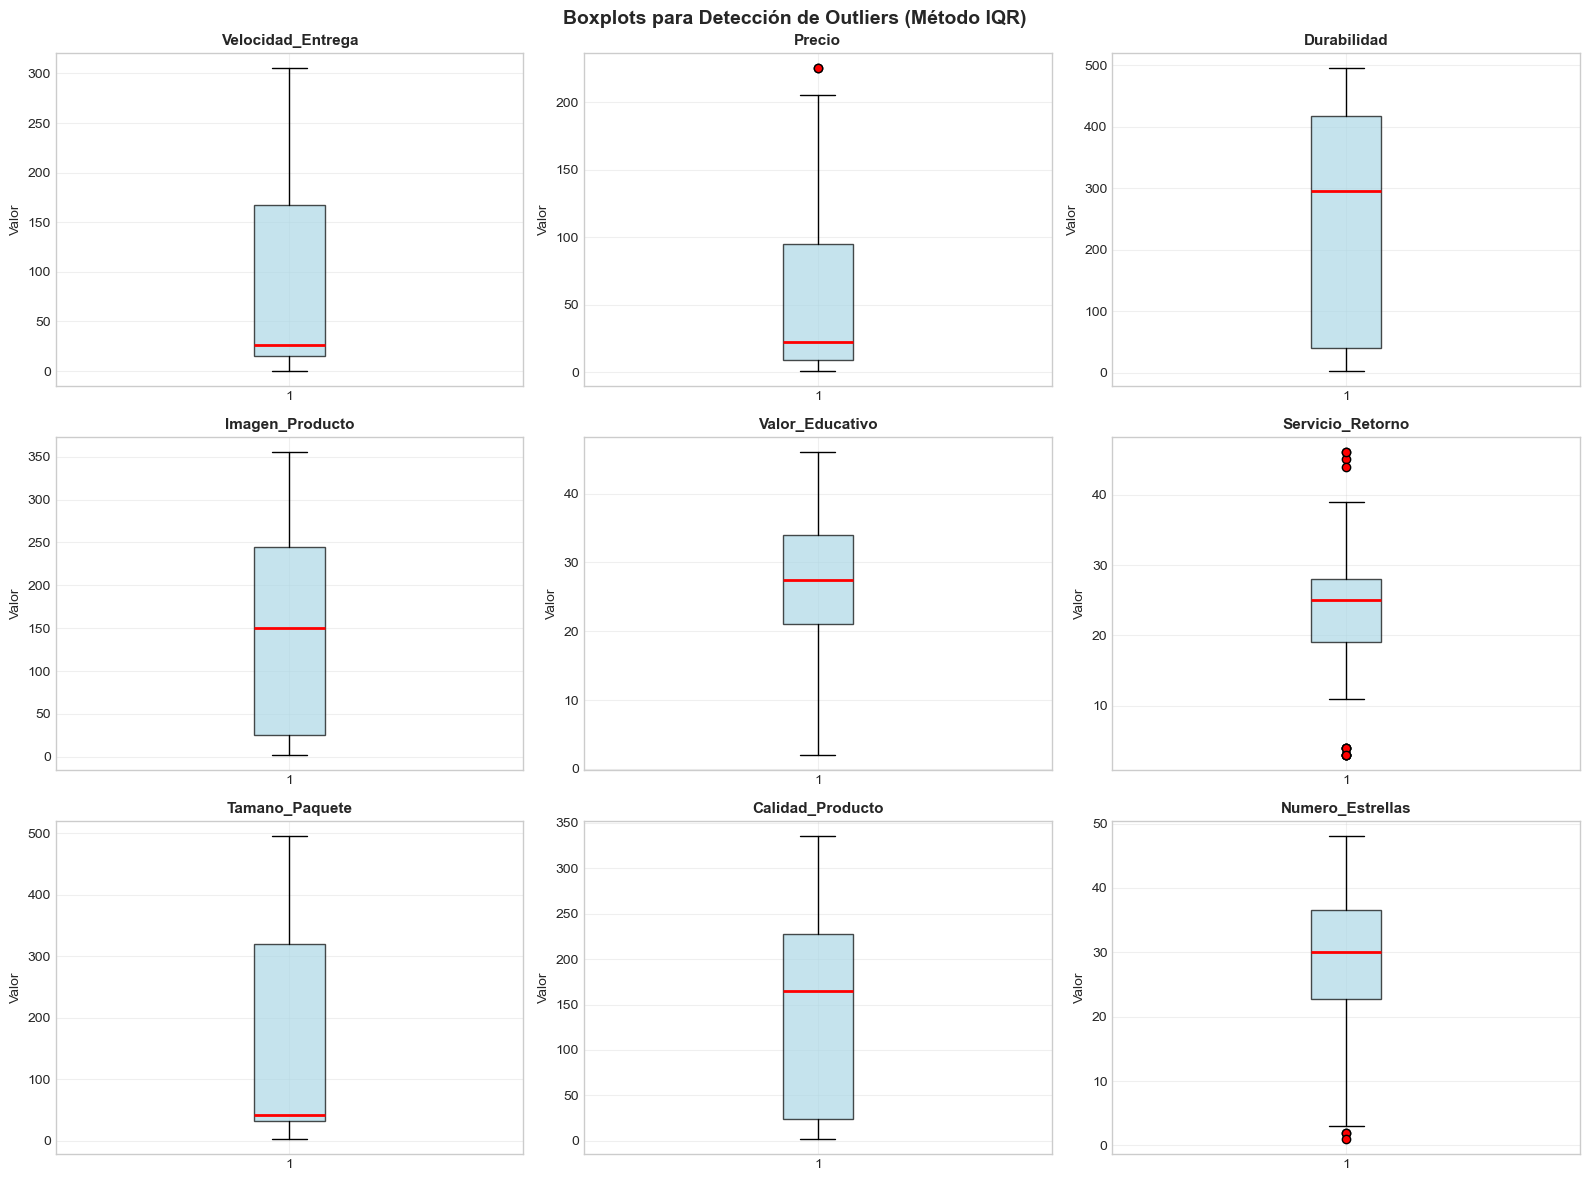

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(df.columns):
    ax = axes[i]
    bp = ax.boxplot(df[col].values, vert=True, patch_artist=True,
                    boxprops=dict(facecolor='lightblue', alpha=0.7),
                    medianprops=dict(color='red', linewidth=2),
                    flierprops=dict(marker='o', markerfacecolor='red', markersize=6))
    ax.set_title(f'{col}', fontsize=11, fontweight='bold')
    ax.set_ylabel('Valor')
    ax.grid(True, alpha=0.3)

plt.suptitle('Boxplots para Detección de Outliers (Método IQR)', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('boxplots_outliers.png', dpi=150, bbox_inches='tight')
plt.show()

# 4. ESTANDARIZACIÓN DE DATOS
 
 El clustering jerárquico es sensible a las escalas de las variables.
 Se aplica StandardScaler para que todas las variables contribuyan 
 equitativamente al cálculo de distancias.

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
X_scaled_df = pd.DataFrame(X_scaled, index=df.index, columns=df.columns)

print("Datos estandarizados (primeras 5 filas):")
print(X_scaled_df.head().round(3))
print("\nEstadísticas de datos estandarizados:")
print(X_scaled_df.describe().round(2))

Datos estandarizados (primeras 5 filas):
         Velocidad_Entrega  Precio  Durabilidad  Imagen_Producto  \
Cliente                                                            
Adam                 1.203  -0.856        0.571            0.752   
Anna                -0.870  -0.670        0.411           -0.915   
Bernard             -0.785  -0.500        0.251           -1.163   
Edward               0.463  -0.825        0.625            1.247   
Emilia              -0.933  -0.206       -1.016           -0.866   

         Valor_Educativo  Servicio_Retorno  Tamano_Paquete  Calidad_Producto  \
Cliente                                                                        
Adam              -0.139            -0.090          -0.796            -0.983   
Anna              -0.050            -2.072          -0.698             0.779   
Bernard            1.553             0.328          -0.704            -0.938   
Edward            -0.673            -0.090          -0.716             0.598   
Em

# CLUSTERING JERÁRQUICO AGLOMERATIVO

In [8]:
# Método de Ward: minimiza la varianza intra-cluster
linkage_matrix = linkage(X_scaled, method='ward')

print("Matriz de linkage generada con método Ward.")
print(f"Forma: {linkage_matrix.shape}")

Matriz de linkage generada con método Ward.
Forma: (99, 4)


# Visualización del Dendrograma

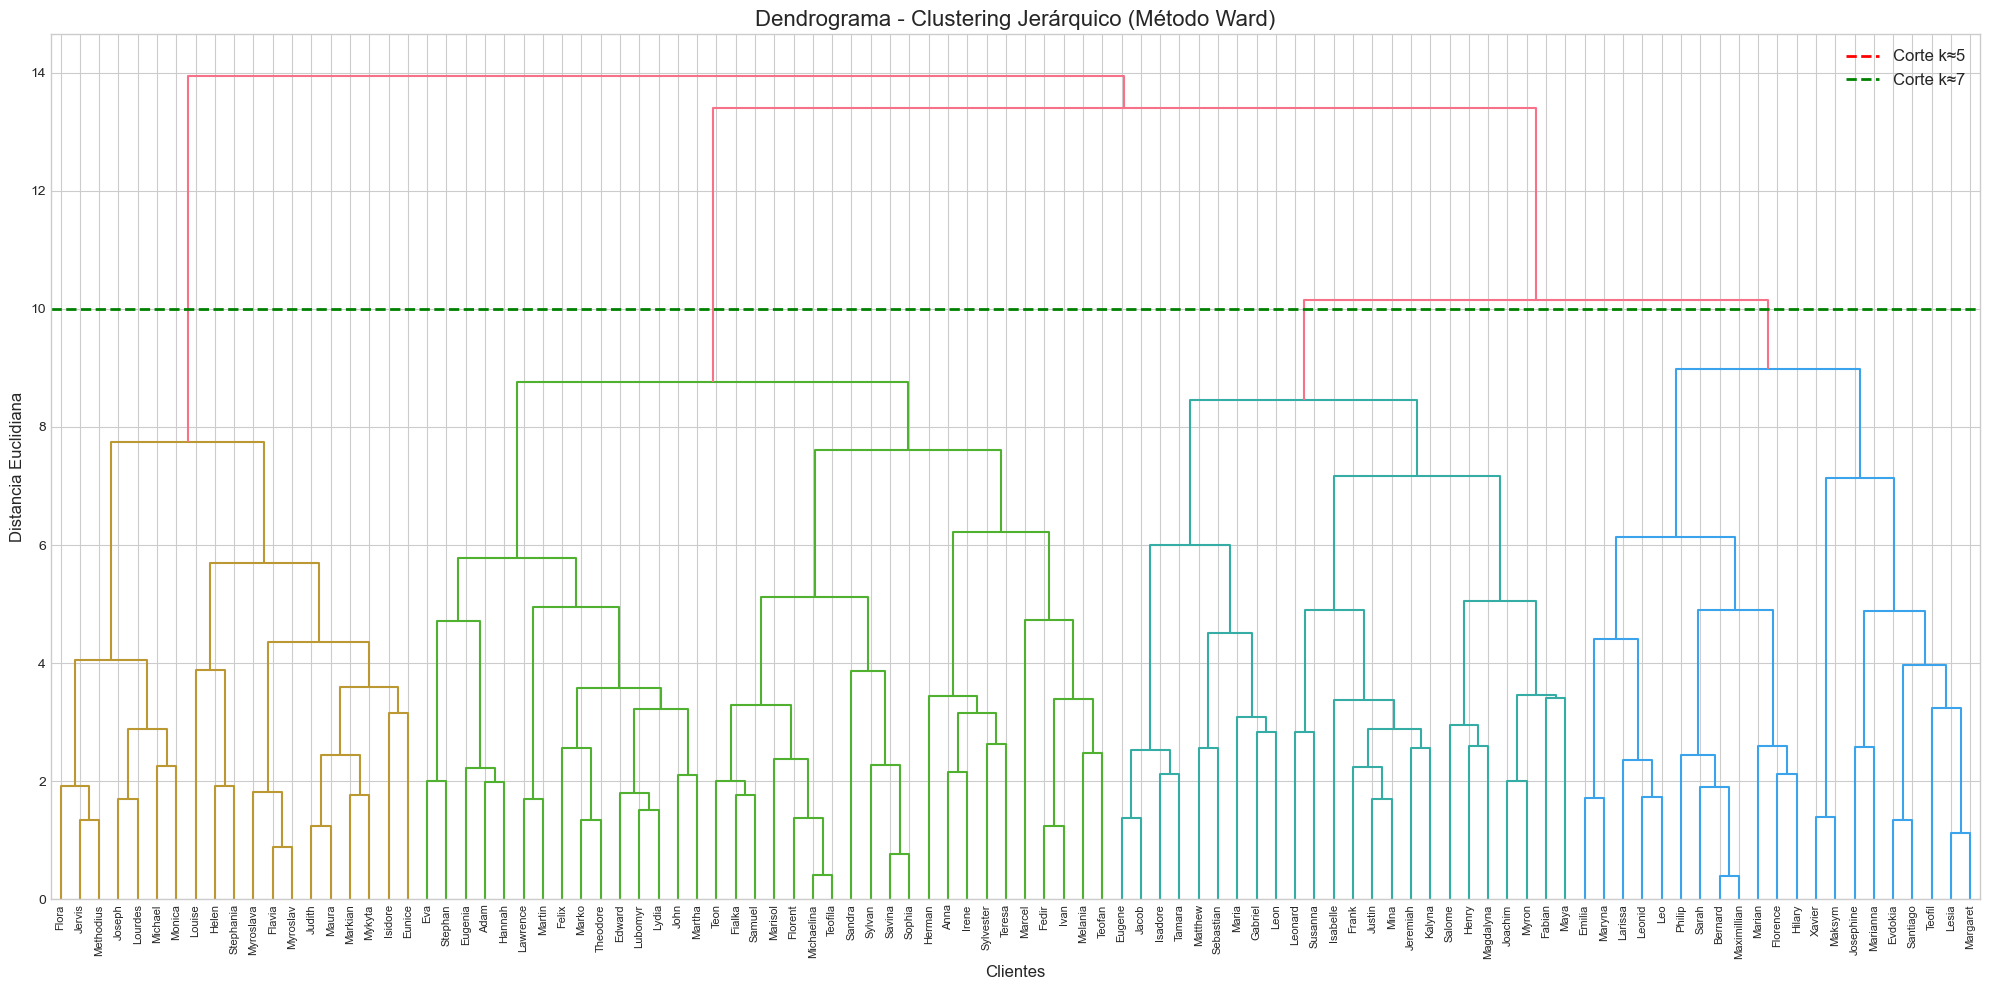

In [9]:
plt.figure(figsize=(20, 10))
dendrogram(linkage_matrix, labels=df.index, leaf_rotation=90, leaf_font_size=8)
plt.title('Dendrograma - Clustering Jerárquico (Método Ward)', fontsize=16)
plt.xlabel('Clientes', fontsize=12)
plt.ylabel('Distancia Euclidiana', fontsize=12)
plt.axhline(y=15, color='r', linestyle='--', linewidth=2, label='Corte k≈5')
plt.axhline(y=10, color='g', linestyle='--', linewidth=2, label='Corte k≈7')
plt.legend(fontsize=12)
plt.tight_layout()
plt.savefig('dendrograma.png', dpi=150, bbox_inches='tight')
plt.show()

# DETERMINACIÓN DEL NÚMERO ÓPTIMO DE CLUSTERS

SILHOUETTE SCORE POR NÚMERO DE CLUSTERS
k =  4  →  Silhouette Score = 0.1077
k =  5  →  Silhouette Score = 0.1067
k =  6  →  Silhouette Score = 0.0986
k =  7  →  Silhouette Score = 0.1071
k =  8  →  Silhouette Score = 0.1051
k =  9  →  Silhouette Score = 0.1133
k = 10  →  Silhouette Score = 0.1248


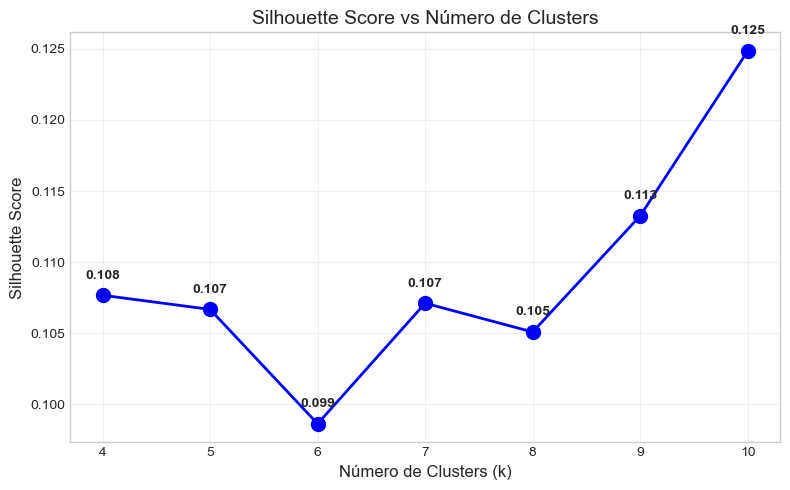


>>> Mejor k según Silhouette Score puro: 10 (score=0.1248)


In [10]:
k_values = range(4, 11)
silhouette_scores = []

print("=" * 50)
print("SILHOUETTE SCORE POR NÚMERO DE CLUSTERS")
print("=" * 50)

for k in k_values:
    clusters = fcluster(linkage_matrix, k, criterion='maxclust')
    score = silhouette_score(X_scaled, clusters)
    silhouette_scores.append(score)
    print(f"k = {k:2d}  →  Silhouette Score = {score:.4f}")

# Visualización
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, 'bo-', linewidth=2, markersize=10)
plt.xlabel('Número de Clusters (k)', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.title('Silhouette Score vs Número de Clusters', fontsize=14)
plt.grid(True, alpha=0.3)
for k, s in zip(k_values, silhouette_scores):
    plt.annotate(f'{s:.3f}', (k, s), textcoords="offset points", 
                xytext=(0, 12), ha='center', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig('silhouette_scores.png', dpi=150, bbox_inches='tight')
plt.show()

best_k_silhouette = k_values[np.argmax(silhouette_scores)]
print(f"\n>>> Mejor k según Silhouette Score puro: {best_k_silhouette} (score={max(silhouette_scores):.4f})")

# Comparación Detallada: k=5 vs k=10

COMPARACIÓN DETALLADA: k=5 vs k=10

--- k = 5 ---
Silhouette Score: 0.1067
Tamaños de clusters:
  Cluster 1: 19 clientes (19%)
  Cluster 2: 36 clientes (36%)
  Cluster 3: 24 clientes (24%)
  Cluster 4: 12 clientes (12%)
  Cluster 5: 9 clientes (9%)
  Cluster más pequeño: 9 clientes
  Cluster más grande: 36 clientes
  Desv. estándar de tamaños: 10.70

--- k = 10 ---
Silhouette Score: 0.1248
Tamaños de clusters:
  Cluster 1: 7 clientes (7%)
  Cluster 2: 12 clientes (12%)
  Cluster 3: 15 clientes (15%)
  Cluster 4: 11 clientes (11%)
  Cluster 5: 10 clientes (10%)
  Cluster 6: 9 clientes (9%)
  Cluster 7: 8 clientes (8%)
  Cluster 8: 7 clientes (7%)
  Cluster 9: 12 clientes (12%)
  Cluster 10: 9 clientes (9%)
  Cluster más pequeño: 7 clientes
  Cluster más grande: 15 clientes
  Desv. estándar de tamaños: 2.54


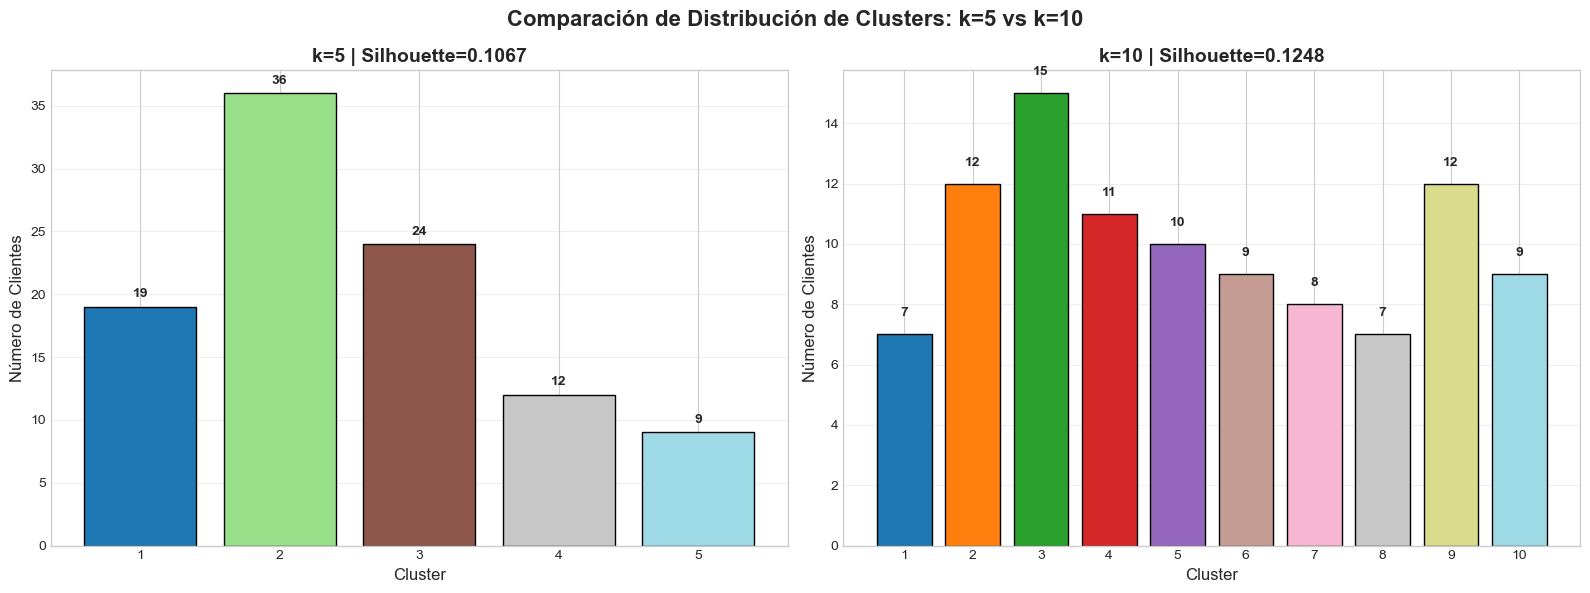

In [11]:

print("COMPARACIÓN DETALLADA: k=5 vs k=10")


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, k in enumerate([5, 10]):
    clusters = fcluster(linkage_matrix, k, criterion='maxclust')
    score = silhouette_score(X_scaled, clusters)
    sizes = pd.Series(clusters).value_counts().sort_index()
    
    print(f"\n--- k = {k} ---")
    print(f"Silhouette Score: {score:.4f}")
    print(f"Tamaños de clusters:")
    for c, s in sizes.items():
        print(f"  Cluster {c}: {s} clientes ({s/100*100:.0f}%)")
    print(f"  Cluster más pequeño: {sizes.min()} clientes")
    print(f"  Cluster más grande: {sizes.max()} clientes")
    print(f"  Desv. estándar de tamaños: {sizes.std():.2f}")
    
    colors = plt.cm.tab20(np.linspace(0, 1, k))
    bars = axes[idx].bar(range(1, k+1), sizes.values, color=colors, edgecolor='black')
    axes[idx].set_xlabel('Cluster', fontsize=12)
    axes[idx].set_ylabel('Número de Clientes', fontsize=12)
    axes[idx].set_title(f'k={k} | Silhouette={score:.4f}', fontsize=14, fontweight='bold')
    axes[idx].set_xticks(range(1, k+1))
    for bar, val in zip(bars, sizes.values):
        axes[idx].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
                      str(val), ha='center', va='bottom', fontsize=10, fontweight='bold')
    axes[idx].grid(True, alpha=0.3, axis='y')

plt.suptitle('Comparación de Distribución de Clusters: k=5 vs k=10', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('comparacion_k5_k10.png', dpi=150, bbox_inches='tight')
plt.show()

# 6.2 Justificación de la Elección de k=5

 Aunque el Silhouette Score indica k=10 como ligeramente superior (0.1248 vs 0.1067),
 se optó por **k=5** por las siguientes razones:
 
 1. **Interpretabilidad:** Con k=5, cada cluster tiene un perfil claramente diferenciado 
    (Premium, Equilibrado, Gran Formato, Valor Educativo, Entrega Rápida). Con k=10, 
    los perfiles se fragmentan y se vuelven redundantes.
 
 2. **Aplicabilidad práctica:** Clusters de 7-15 clientes (k=10) son demasiado pequeños 
    para generar recomendaciones robustas. Con k=5 (9-36 clientes por cluster), las 
    recomendaciones tienen base estadística suficiente.
 
 3. **Parsimonia:** La diferencia de Silhouette (0.0181) no justifica duplicar la 
    complejidad del modelo. El principio de Ockham favorece la solución más simple 
    cuando la mejora es marginal.
 
 4. **Objetivo del negocio:** El ejercicio busca segmentos accionables para 
    recomendaciones. Cinco segmentos son manejables para un equipo de marketing; 
    diez segmentos generan confusión operativa.

In [12]:
k_final = 5
clusters_final = fcluster(linkage_matrix, k_final, criterion='maxclust')
df_cluster = df.copy()
df_cluster['Cluster'] = clusters_final

print(f"\n>>> CLUSTER SELECCIONADO PARA EL ANÁLISIS: k = {k_final}")
print(f"\nDistribución de clientes por cluster:")
print(df_cluster['Cluster'].value_counts().sort_index())


>>> CLUSTER SELECCIONADO PARA EL ANÁLISIS: k = 5

Distribución de clientes por cluster:
Cluster
1    19
2    36
3    24
4    12
5     9
Name: count, dtype: int64


#  CARACTERIZACIÓN COMPLETA DE LOS 5 CLUSTERS

In [13]:

print("PERFILES PROMEDIO POR CLUSTER")


cluster_profiles = df_cluster.groupby('Cluster').mean().round(1)
print(cluster_profiles.to_string())

PERFILES PROMEDIO POR CLUSTER
         Velocidad_Entrega  Precio  Durabilidad  Imagen_Producto  Valor_Educativo  Servicio_Retorno  Tamano_Paquete  Calidad_Producto  Numero_Estrellas
Cluster                                                                                                                                                
1                    153.2    58.5        440.3            188.5             30.7              21.8           112.1             264.5              37.1
2                     72.2    35.7        211.0            137.5             20.6              20.7            61.4             124.8              17.8
3                     50.9   102.3        182.2            168.8             22.0              27.5           336.3              80.9              28.6
4                     29.6    56.9        257.6             89.8             35.0              30.8           127.2              22.8              37.9
5                    226.1    33.4         42.7           

# Descripción de cada Cluster:
 
 **CLUSTER 1 - Premium Alta Calidad (19 clientes, 19%)**
 - Destacado en: Durabilidad (440.3), Calidad_Producto (264.5), Numero_Estrellas (37.1)
 - Perfil: Clientes exigentes que priorizan durabilidad extrema y calidad. 
   Pagan precios moderados-altos. Valoran velocidad de entrega.
 
 **CLUSTER 2 - Equilibrado/Económico (36 clientes, 36%)**
 - Destacado en: Precio bajo (35.7), Durabilidad moderada (211.0)
 - Perfil: Grupo más grande. Buscan balance calidad-precio. No exigentes 
   con velocidad ni calificaciones extremas.
 
 **CLUSTER 3 - Gran Formato/Precio Elevado (24 clientes, 24%)**
 - Destacado en: Tamano_Paquete (336.3), Precio (102.3)
 - Perfil: Compran productos voluminosos caros. Curiosamente, calidad baja (80.9).
   No valoran velocidad de entrega ni valor educativo.
 
 **CLUSTER 4 - Valor Educativo/Servicio (12 clientes, 12%)**
 - Destacado en: Valor_Educativo (35.0), Servicio_Retorno (30.8), Estrellas (37.9)
 - Perfil: Priorizan aprendizaje y servicio post-venta. Nicho pequeño pero fiel.
   Calidad técnica baja (22.8), no les importa velocidad ni imagen.
 
 **CLUSTER 5 - Entrega Rápida/Baja Durabilidad (9 clientes, 9%)**
 - Destacado en: Velocidad_Entrega (226.1), Tamano_Paquete (182.1)
 - Perfil: Clientes impacientes. Compran productos desechables/baratos de baja 
   durabilidad (42.7). Solo les importa que llegue rápido.

# 7.1 Visualización Radar de los 5 Clusters

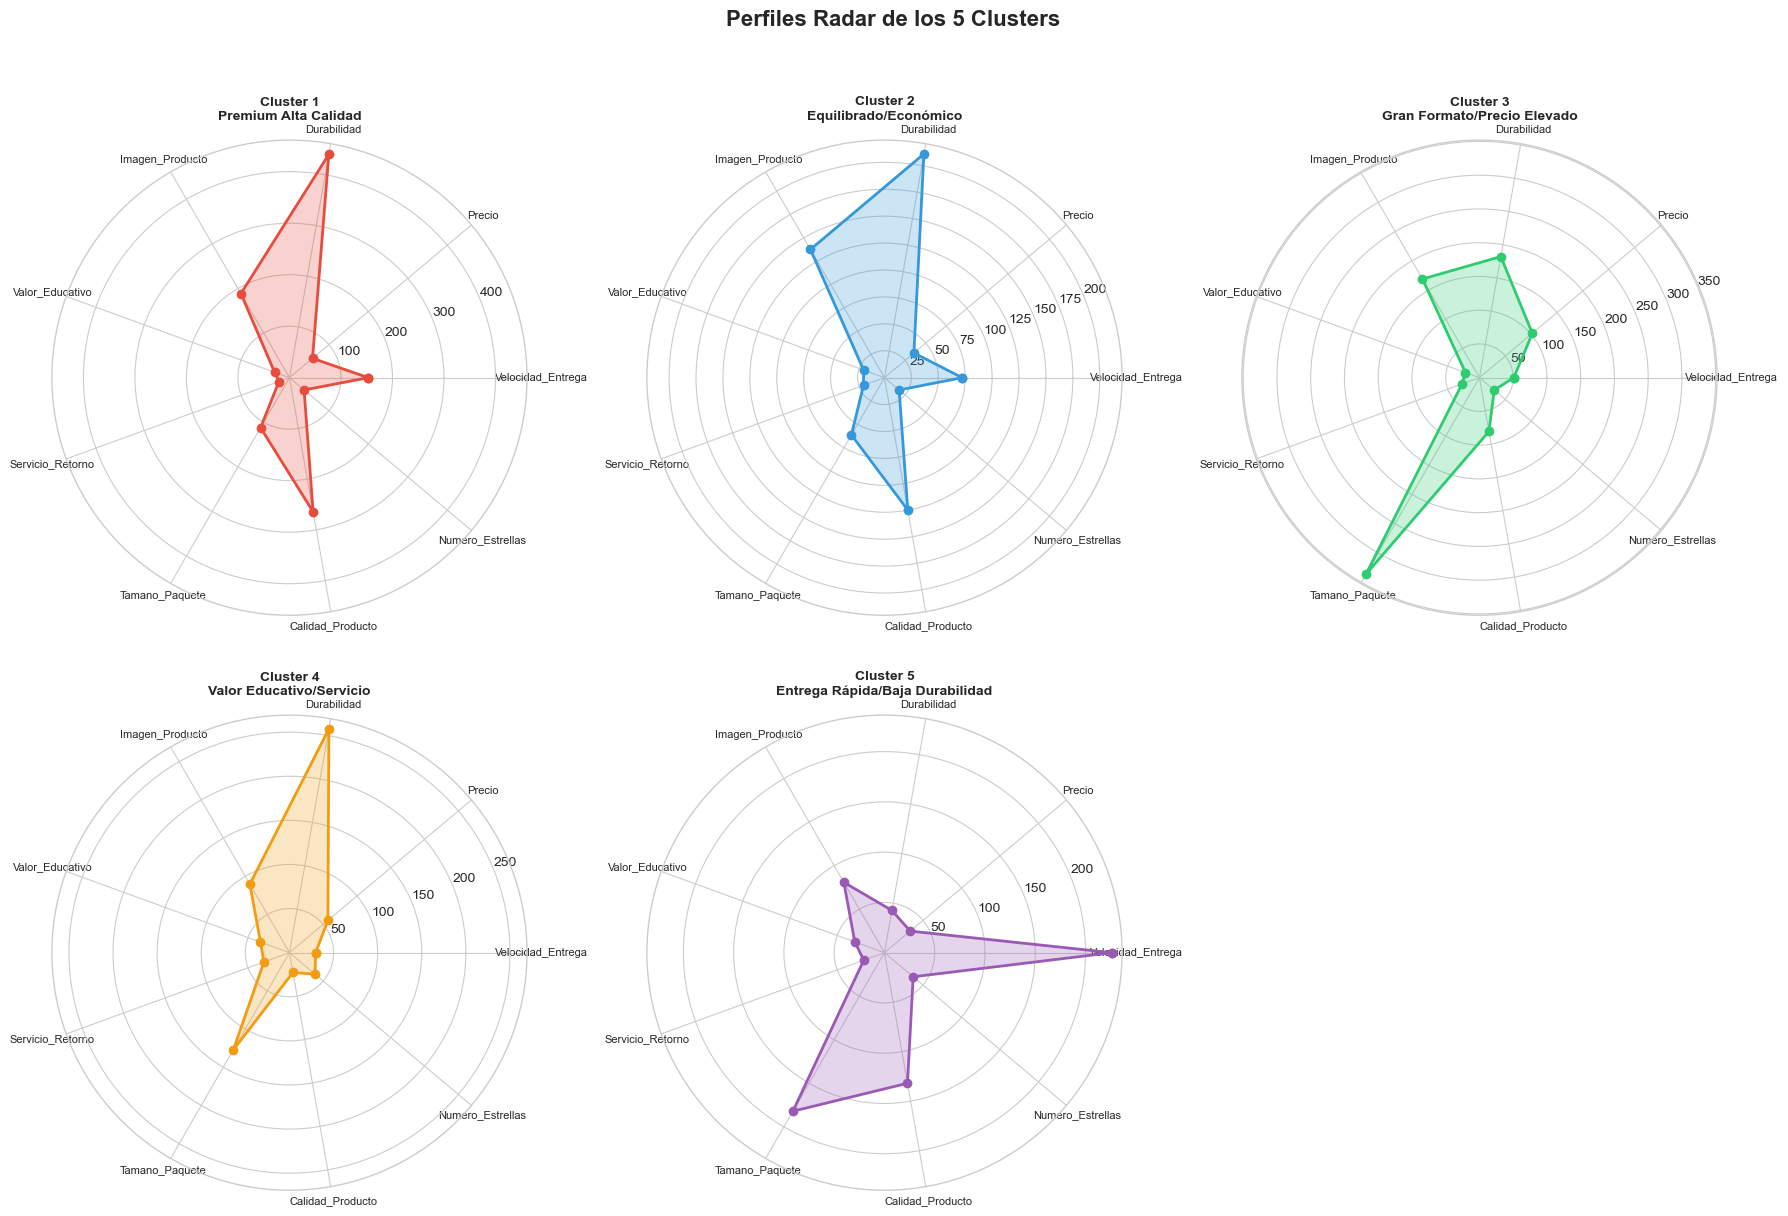

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12), subplot_kw=dict(polar=True))
axes = axes.flatten()

categories = df.columns.tolist()
N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

colors_radar = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6']
cluster_names = ['Premium Alta Calidad', 'Equilibrado/Económico', 
                 'Gran Formato/Precio Elevado', 'Valor Educativo/Servicio', 
                 'Entrega Rápida/Baja Durabilidad']

for idx, (ax, c_id) in enumerate(zip(axes[:5], range(1, 6))):
    values = cluster_profiles.loc[c_id].values.tolist()
    values += values[:1]
    
    ax.plot(angles, values, 'o-', linewidth=2, color=colors_radar[c_id-1])
    ax.fill(angles, values, alpha=0.25, color=colors_radar[c_id-1])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize=8)
    ax.set_title(f'Cluster {c_id}\n{cluster_names[c_id-1]}', 
                 fontsize=10, fontweight='bold', pad=15)

axes[5].axis('off')
plt.suptitle('Perfiles Radar de los 5 Clusters', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('radar_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

#  ANÁLISIS DE VECINOS MÁS CERCANOS Y RECOMENDACIONES

In [15]:
def find_nearest_neighbors(cliente, n_neighbors=5):
    """
    Encuentra los vecinos más cercanos dentro del mismo cluster
    usando distancia euclidiana en el espacio estandarizado.
    """
    cluster_id = df_cluster.loc[cliente, 'Cluster']
    same_cluster = df_cluster[df_cluster['Cluster'] == cluster_id].index.tolist()
    same_cluster.remove(cliente)
    
    cliente_vec = X_scaled_df.loc[cliente].values.reshape(1, -1)
    others_vec = X_scaled_df.loc[same_cluster].values
    distances = cdist(cliente_vec, others_vec, metric='euclidean')[0]
    
    dist_df = pd.DataFrame({
        'Cliente': same_cluster,
        'Distancia_Euclidiana': distances
    }).sort_values('Distancia_Euclidiana')
    
    return dist_df.head(n_neighbors), cluster_id


def analizar_recomendaciones(cliente, n_neighbors=5):
    """
    Analiza un cliente objetivo, encuentra sus vecinos más cercanos
    en el mismo cluster e identifica productos recomendados.
    """
    neighbors, cluster_id = find_nearest_neighbors(cliente, n_neighbors)
    neighbor_names = neighbors['Cliente'].tolist()
    
    print(f"\n{'='*80}")
    print(f"ANÁLISIS PARA: {cliente} | Cluster: {cluster_id}")
    print(f"Vecinos más cercanos: {', '.join(neighbor_names)}")
    print(f"{'='*80}")
    
    cliente_data = df.loc[cliente]
    neighbors_data = df.loc[neighbor_names]
    
    # Comparación con promedio de vecinos
    comparison = pd.DataFrame({
        cliente: cliente_data.values,
        'Promedio_Vecinos': neighbors_data.mean().values,
        'Diferencia': neighbors_data.mean().values - cliente_data.values
    }, index=df.columns).round(1)
    print("\nComparación con promedio de vecinos:")
    print(comparison.to_string())
    
    # Productos recomendados (diferencia > 30 puntos)
    print(f"\nProductos donde vecinos valoran significativamente más alto (>30 puntos):")
    recomendaciones = []
    for producto in df.columns:
        valor_cliente = cliente_data[producto]
        promedio_vecinos = neighbors_data[producto].mean()
        diferencia = promedio_vecinos - valor_cliente
        if diferencia > 30:
            recomendaciones.append({
                'Producto': producto,
                f'{cliente}': valor_cliente,
                'Prom_Vecinos': round(promedio_vecinos, 1),
                'Diferencia': round(diferencia, 1)
            })
    
    if recomendaciones:
        rec_df = pd.DataFrame(recomendaciones).sort_values('Diferencia', ascending=False)
        print(rec_df.to_string(index=False))
    else:
        print("No hay productos con diferencias significativas (>30 puntos).")
    
    # Análisis vecino por vecino
    print(f"\nDiferencias significativas por vecino individual (>30 puntos):")
    for vecino in neighbor_names:
        vecino_data = df.loc[vecino]
        diffs = vecino_data - cliente_data
        destacados = diffs[diffs > 30].sort_values(ascending=False)
        if len(destacados) > 0:
            print(f"\n  {vecino}:")
            for prod, diff in destacados.items():
                print(f"    - {prod}: {cliente}={cliente_data[prod]}, "
                      f"{vecino}={vecino_data[prod]} (dif=+{diff})")
    
    return neighbor_names

# Recomendaciones para SALOMÉ

In [16]:
vecinos_salome = analizar_recomendaciones('Salome', n_neighbors=5)


ANÁLISIS PARA: Salome | Cluster: 3
Vecinos más cercanos: Magdalyna, Henry, Susanna, Myron, Joachim

Comparación con promedio de vecinos:
                   Salome  Promedio_Vecinos  Diferencia
Velocidad_Entrega      17              72.0        55.0
Precio                 23              47.6        24.6
Durabilidad           275             315.8        40.8
Imagen_Producto        41             133.0        92.0
Valor_Educativo         4              12.0         8.0
Servicio_Retorno       44              31.2       -12.8
Tamano_Paquete        315             427.0       112.0
Calidad_Producto       28              85.6        57.6
Numero_Estrellas       32              27.2        -4.8

Productos donde vecinos valoran significativamente más alto (>30 puntos):
         Producto  Salome  Prom_Vecinos  Diferencia
   Tamano_Paquete     315         427.0       112.0
  Imagen_Producto      41         133.0        92.0
 Calidad_Producto      28          85.6        57.6
Velocidad_Entrega  

# **CONCLUSIÓN PARA SALOMÉ:**
 
 Salomé pertenece al **Cluster 3** (Gran Formato/Precio Elevado).
 Sus vecinos más cercanos: Magdalyna (2.77), Henry (2.97), Susanna (3.00), 
 Myron (3.13) y Joachim (3.32).
 
 **Recomendación:** "Recomendaría a Salomé los mismos productos que compró 
 **Myron** y **Joachim**."
 
 - Myron valora mucho más: Tamaño Paquete (495 vs 315), Imagen Producto (225 vs 41),
   Calidad Producto (165 vs 28), Durabilidad (355 vs 275).
 - Joachim valora mucho más: Calidad Producto (195 vs 28), Tamaño Paquete (445 vs 315),
   Precio (105 vs 23), Durabilidad (345 vs 275).
 
 Salomé subvalora atributos de calidad e imagen dentro de su segmento de gran formato.

#  Recomendaciones para STEPHANIA

In [17]:
vecinos_stephania = analizar_recomendaciones('Stephania', n_neighbors=5)


ANÁLISIS PARA: Stephania | Cluster: 1
Vecinos más cercanos: Judith, Helen, Maura, Mykyta, Markian

Comparación con promedio de vecinos:
                   Stephania  Promedio_Vecinos  Diferencia
Velocidad_Entrega        215             217.0         2.0
Precio                   125              90.6       -34.4
Durabilidad              465             427.0       -38.0
Imagen_Producto          315             225.0       -90.0
Valor_Educativo           34              32.8        -1.2
Servicio_Retorno           4              15.4        11.4
Tamano_Paquete            37              32.0        -5.0
Calidad_Producto         305             257.0       -48.0
Numero_Estrellas          45              35.2        -9.8

Productos donde vecinos valoran significativamente más alto (>30 puntos):
No hay productos con diferencias significativas (>30 puntos).

Diferencias significativas por vecino individual (>30 puntos):

  Helen:
    - Precio: Stephania=125, Helen=185 (dif=+60)

  Maura:
   

# **CONCLUSIÓN PARA STEPHANIA:**
 
 Stephania pertenece al **Cluster 1** (Premium Alta Calidad).
 Sus vecinos más cercanos: Judith (1.40), Helen (1.91), Maura (2.24),
 Mykyta (2.79) y Markian (3.01).
 
 **Recomendación:** "Recomendaría a Stephania los mismos productos que compró 
 **Markian** y **Maura**."
 
 - Markian valora más: Servicio de Retorno (27 vs 4), Durabilidad (465), 
   Calidad Producto (265).
 - Maura valora más: Velocidad de Entrega (265 vs 215), Servicio Retorno (19 vs 4).
 
 Stephania descuida el Servicio de Retorno dentro de su segmento premium.

#  Recomendaciones para LYDIA

In [18]:
vecinos_lydia = analizar_recomendaciones('Lydia', n_neighbors=5)



ANÁLISIS PARA: Lydia | Cluster: 2
Vecinos más cercanos: Lubomyr, Fialka, Edward, Fedir, Irene

Comparación con promedio de vecinos:
                   Lydia  Promedio_Vecinos  Diferencia
Velocidad_Entrega     19              38.4        19.4
Precio                 4              20.2        16.2
Durabilidad          435             369.0       -66.0
Imagen_Producto      145             141.6        -3.4
Valor_Educativo       16              19.0         3.0
Servicio_Retorno      21              21.0         0.0
Tamano_Paquete        28              36.0         8.0
Calidad_Producto     185             150.4       -34.6
Numero_Estrellas      24              16.2        -7.8

Productos donde vecinos valoran significativamente más alto (>30 puntos):
No hay productos con diferencias significativas (>30 puntos).

Diferencias significativas por vecino individual (>30 puntos):

  Lubomyr:
    - Imagen_Producto: Lydia=145, Lubomyr=245 (dif=+100)

  Fialka:
    - Precio: Lydia=4, Fialka=75 (di

# **CONCLUSIÓN PARA LYDIA:**
 
 Lydia pertenece al **Cluster 2** (Equilibrado/Económico).
 Sus vecinos más cercanos: Lubomyr (1.51), Fialka (1.68), Edward (1.92),
 Fedir (1.98) e Irene (2.01).
 
 **Recomendación:** "Recomendaría a Lydia los mismos productos que compró 
 **Edward** y **Lubomyr**."
 
 - Edward valora mucho más: Imagen Producto (295 vs 145), Velocidad Entrega (135 vs 19).
 - Lubomyr valora más: Imagen Producto (245 vs 145), Valor Educativo (25 vs 16).
 
 Lydia subvalora la imagen del producto y la velocidad de entrega.

 #  VISUALIZACIÓN DE CLUSTERS EN ESPACIO PCA

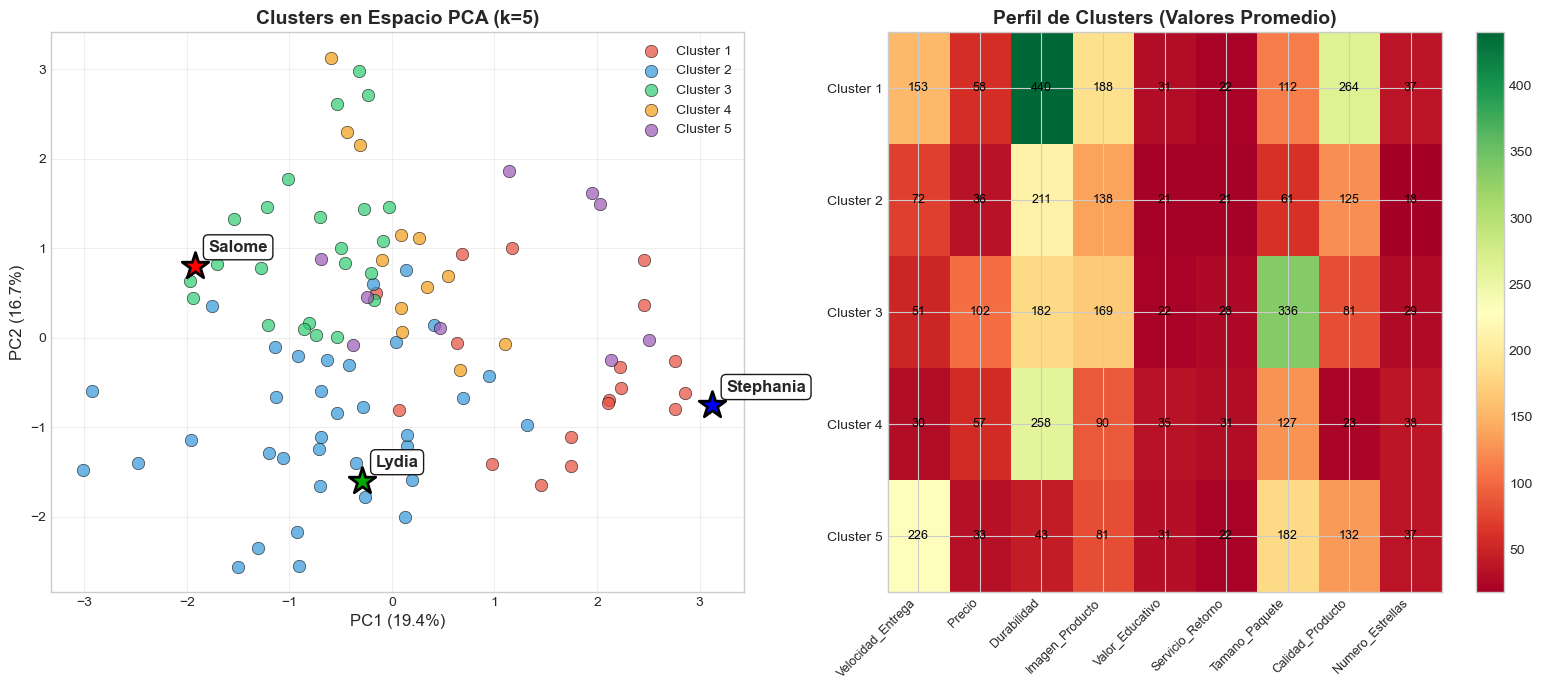


Varianza explicada por PCA: PC1=19.4%, PC2=16.7%


In [19]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Plot 1: Clusters con clientes objetivo destacados
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6']
cluster_labels = df_cluster['Cluster'].values

for i in range(1, 6):
    mask = cluster_labels == i
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], 
                   c=colors[i-1], label=f'Cluster {i}', s=80, alpha=0.7, 
                   edgecolors='black', linewidth=0.5)

# Destacar clientes objetivo
obj_colors = {'Salome': '#ff0000', 'Stephania': '#0000ff', 'Lydia': '#00aa00'}
for cliente in ['Salome', 'Stephania', 'Lydia']:
    idx = df.index.get_loc(cliente)
    axes[0].scatter(X_pca[idx, 0], X_pca[idx, 1], 
                   c=obj_colors[cliente], s=400, marker='*', 
                   edgecolors='black', linewidth=2, zorder=5)
    axes[0].annotate(cliente, (X_pca[idx, 0], X_pca[idx, 1]), 
                    xytext=(10, 10), textcoords='offset points', 
                    fontsize=12, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.9))

axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
axes[0].set_title('Clusters en Espacio PCA (k=5)', fontsize=14, fontweight='bold')
axes[0].legend(loc='best')
axes[0].grid(True, alpha=0.3)

# Plot 2: Heatmap de perfiles
im = axes[1].imshow(cluster_profiles.values, cmap='RdYlGn', aspect='auto')
axes[1].set_xticks(range(len(cluster_profiles.columns)))
axes[1].set_xticklabels(cluster_profiles.columns, rotation=45, ha='right', fontsize=9)
axes[1].set_yticks(range(len(cluster_profiles.index)))
axes[1].set_yticklabels([f'Cluster {i}' for i in cluster_profiles.index], fontsize=10)
axes[1].set_title('Perfil de Clusters (Valores Promedio)', fontsize=14, fontweight='bold')

for i in range(len(cluster_profiles.index)):
    for j in range(len(cluster_profiles.columns)):
        text = axes[1].text(j, i, f'{cluster_profiles.values[i, j]:.0f}',
                           ha="center", va="center", color="black", fontsize=9)

plt.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.savefig('clusters_visualizacion.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nVarianza explicada por PCA: "
      f"PC1={pca.explained_variance_ratio_[0]*100:.1f}%, "
      f"PC2={pca.explained_variance_ratio_[1]*100:.1f}%")

# RESUMEN FINAL DE RECOMENDACIONES


In [20]:
print("""
╔══════════════════════════════════════════════════════════════════════════════╗
║                    RESUMEN DE RECOMENDACIONES FINALES                        ║
╠══════════════════════════════════════════════════════════════════════════════╣
║                                                                              ║
║  SALOMÉ (Cluster 3 - Gran Formato/Precio Elevado)                           ║
║  → Recomendar los mismos productos que: Myron y Joachim                      ║
║  → Razón: Valoran más alto Calidad, Imagen, Durabilidad y Tamaño Paquete    ║
║                                                                              ║
║  STEPHANIA (Cluster 1 - Premium Alta Calidad)                               ║
║  → Recomendar los mismos productos que: Markian y Maura                      ║
║  → Razón: Valoran más alto Servicio Retorno y Velocidad Entrega             ║
║                                                                              ║
║  LYDIA (Cluster 2 - Equilibrado/Económico)                                  ║
║  → Recomendar los mismos productos que: Edward y Lubomyr                     ║
║  → Razón: Valoran más alto Imagen Producto y Velocidad Entrega              ║
║                                                                              ║
╚══════════════════════════════════════════════════════════════════════════════╝
""")


╔══════════════════════════════════════════════════════════════════════════════╗
║                    RESUMEN DE RECOMENDACIONES FINALES                        ║
╠══════════════════════════════════════════════════════════════════════════════╣
║                                                                              ║
║  SALOMÉ (Cluster 3 - Gran Formato/Precio Elevado)                           ║
║  → Recomendar los mismos productos que: Myron y Joachim                      ║
║  → Razón: Valoran más alto Calidad, Imagen, Durabilidad y Tamaño Paquete    ║
║                                                                              ║
║  STEPHANIA (Cluster 1 - Premium Alta Calidad)                               ║
║  → Recomendar los mismos productos que: Markian y Maura                      ║
║  → Razón: Valoran más alto Servicio Retorno y Velocidad Entrega             ║
║                                                                              ║
║  LYDIA (Cluster 2 - Equilibra

# CONCLUSIONES GENERALES
 
 1. **Limpieza de datos:** El dataset estaba consistente desde el origen. 
    No se requirió imputación ni eliminación de registros. Los outliers detectados 
    fueron valores plausibles de opiniones extremas.
 
 2. **Segmentación:** El clustering jerárquico con k=5 identificó 5 perfiles 
    claramente diferenciados de clientes Amazon, cada uno con preferencias 
    distintivas y accionables para el negocio.
 
 3. **Recomendaciones:** La estrategia de vecinos más cercanos dentro del mismo 
    cluster maximiza la relevancia de las recomendaciones, ya que provienen de 
    clientes con perfiles estadísticamente similares.
 
 4. **Clusters 4 y 5:** Aunque no contenían a los clientes objetivo, representan 
    nichos importantes: clientes enfocados en valor educativo/servicio post-venta 
    (Cluster 4) y clientes impacientes que prefieren productos desechables 
    de bajo costo (Cluster 5).